# Otimizador de margem — modelo estrito

Este notebook implementa a primeira versão do otimizador de preços da Minerva. Ele usa a curva de
demanda escolhida nos notebooks 2.0 e 2.0.1 e procura a sequência de preços diários que maximiza a
margem das duas semanas de planejamento.

**Pergunta:** existe um plano de preços que cumpra todas as regras atuais? Se não existir, por quê?

Nesta versão, todas as regras são obrigatórias. O notebook 3.2 tratará os casos em que as regras não
podem ser cumpridas, medindo quanto falta e quanto negociar de cada uma. O planejamento completo
está em `docs/planejamento/plano-otimizador-margem.md`.

## 1. Modelo matemático

Para cada dia útil $t$ do horizonte escolhe-se um preço $p_t$. A curva de demanda transforma esse
preço em volume previsto $q_t(p_t)$, e a margem do dia é a receita líquida de imposto menos o custo
do volume vendido. O modelo estrito é:

$$\max_{p}\ \sum_{t}\big[(1-\tau)\,p_t - c\big]\, q_t(p_t)$$

sujeito a:

| Restrição | Fórmula | Significado |
|---|---|---|
| Meta semanal | $\underline Q \le \sum_{t \in T_w} q_t(p_t) \le \overline Q$ | O volume de cada semana fica dentro da faixa da meta |
| Variação e âncora | $\lvert p_t - p_{t-1}\rvert \le \Delta_t$, com $p_0 = p^{ant}$ | O preço não muda mais que o limite entre dias consecutivos; no primeiro dia, a referência é o último preço praticado |
| Faixa de preço | $\underline p_{c(t)} \le p_t \le \overline p_{c(t)}$ | Nenhum preço fora da faixa já observada para aquele tipo de dia |

A curva é a do campeão P3: $q_t(p) = A_{c(t)}\,p^{\beta}$, em que $\beta$ é a elasticidade e
$A_{c}$ é o nível de demanda de segunda a quinta ou de sexta, já corrigido pelo fator de smearing.
O otimizador usa a curva congelada e não reestima nenhum parâmetro.

O volume não é uma decisão: ele é consequência do preço. Por isso, o modelo tem uma única decisão
por dia.

In [1]:
from pathlib import Path
import json
import os
import time

ROOT = Path.cwd()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
os.chdir(ROOT)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.optimize import Bounds, LinearConstraint, milp
from scipy.sparse import lil_matrix, vstack

CURVA_PATH = ROOT / 'models/demand_curve_champion.json'
DATA_PATH = ROOT / 'data/processed/minerva_modelagem_treino.csv'
RESTRICOES_PATH = ROOT / 'data/interim/minerva_restricoes.csv'
FIGURES_DIR = ROOT / 'reports/figures'
TABLES_DIR = ROOT / 'reports/tables'
for directory in [FIGURES_DIR, TABLES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

ORDEM_DIAS = ['Segunda', 'Terça', 'Quarta', 'Quinta', 'Sexta', 'Sábado', 'Domingo']
IMPOSTO = 0.07
PASSO_GRADE = 0.50
LIMITE_TEMPO_S = 60
CORES = {'Segunda_a_Quinta': '#4c72b0', 'Sexta': '#dd8452'}
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 40)

## 2. Entradas

O notebook usa apenas informações disponíveis antes do início do planejamento:

- **curva de demanda:** artefato congelado no notebook 2.0;
- **último preço praticado:** preço de 31/10/2025, último dia do desenvolvimento. É a referência da
  âncora;
- **custo por kg:** média ponderada pelo volume da última semana do desenvolvimento. É a estimativa
  mais recente do custo antes do horizonte;
- **imposto:** 7% sobre a receita, definido pelo projeto;
- **meta, tolerância e variação máxima:** arquivo de restrições da instância.

O horizonte são os dez dias úteis seguintes ao fim do desenvolvimento. O conjunto de teste não é
carregado.

In [2]:
curva = json.loads(CURVA_PATH.read_text(encoding='utf-8'))
dados = pd.read_csv(DATA_PATH, parse_dates=['data', 'inicio_semana']).sort_values('data')
restricoes = pd.read_csv(RESTRICOES_PATH)

colunas_regra = [
    'Meta (kg)', 'Tolerância %', 'Variação Máxima Preço Entre Dias Consecutivos (R$)',
]
if (restricoes[colunas_regra].nunique() > 1).any():
    raise ValueError('As duas semanas têm regras diferentes; o notebook assume regras iguais.')

ultima_semana = dados.loc[dados['inicio_semana'] == dados['inicio_semana'].max()]
PRECO_ANTERIOR = float(dados['preco_kg'].iloc[-1])
CUSTO_KG = float(ultima_semana['custo_rs'].sum() / ultima_semana['volume_kg'].sum())
META_KG = float(restricoes['Meta (kg)'].iloc[0])
TOLERANCIA = float(restricoes['Tolerância %'].iloc[0])
DELTA_REGRA = float(
    restricoes['Variação Máxima Preço Entre Dias Consecutivos (R$)'].iloc[0]
)

primeira_segunda = dados['data'].max() + pd.offsets.Week(weekday=0)
horizonte = pd.DataFrame({'data': pd.bdate_range(primeira_segunda, periods=10)})
horizonte['dia_semana'] = horizonte['data'].dt.dayofweek.map(dict(enumerate(ORDEM_DIAS)))
horizonte['semana'] = np.repeat([1, 2], 5)
horizonte['contexto'] = horizonte['dia_semana'].map(curva['calendar']['mapping'])

premissas = pd.DataFrame({
    'Parâmetro': [
        'Horizonte', 'Último preço praticado (R$/kg)', 'Custo (R$/kg)', 'Imposto sobre a receita',
        'Meta semanal (kg)', 'Tolerância', 'Faixa semanal (kg)',
        'Variação máxima entre dias (R$/kg)',
    ],
    'Valor': [
        f"{horizonte['data'].min():%d/%m/%Y} a {horizonte['data'].max():%d/%m/%Y}",
        f'{PRECO_ANTERIOR:.2f}', f'{CUSTO_KG:.2f}', f'{IMPOSTO:.0%}',
        f'{META_KG:.0f}', f'{TOLERANCIA:.0%}',
        f'{META_KG * (1 - TOLERANCIA):.1f} a {META_KG * (1 + TOLERANCIA):.1f}',
        f'{DELTA_REGRA:.2f}',
    ],
    'Origem': [
        '10 dias úteis após o desenvolvimento', '31/10/2025', 'Última semana do desenvolvimento',
        'Definição do projeto', 'Instância', 'Instância', 'Meta × (1 ± tolerância)', 'Instância',
    ],
})
display(premissas)

,Parâmetro,Valor,Origem
0,Horizonte,03/11/2025 a 14/11/2025,10 dias úteis após o desenvolvimento
1,Último preço praticado (R$/kg),1318.92,31/10/2025
2,Custo (R$/kg),1004.97,Última semana do desenvolvimento
3,Imposto sobre a receita,7%,Definição do projeto
4,Meta semanal (kg),165,Instância
5,Tolerância,30%,Instância
6,Faixa semanal (kg),115.5 a 214.5,Meta × (1 ± tolerância)
7,Variação máxima entre dias (R$/kg),2.00,Instância


**Resultado das entradas.** O horizonte vai de 03/11 a 14/11/2025, com dez dias úteis em duas semanas. O último preço praticado é `R$ 1.318,92/kg`, e o custo estimado é `R$ 1.004,97/kg`. Com meta de `165 kg` e tolerância de `30%`, cada semana precisa vender entre `115,5` e `214,5 kg`. O preço pode variar no máximo `R$ 2,00` entre dias consecutivos, inclusive do último preço praticado para o primeiro dia.

## 3. Curva de demanda no horizonte

Antes de otimizar, vale olhar o que a curva diz sobre cada tipo de dia. Para cada contexto, a célula
calcula o nível de demanda $A_c$ e a faixa de preço permitida. Também calcula o preço que maximizaria
a margem de um dia isolado, sem nenhuma restrição:

$$p^* = \frac{c}{1-\tau}\cdot\frac{\beta}{\beta+1}$$

Esse preço não depende do dia da semana, porque a elasticidade é a mesma para todos os dias.

In [3]:
coeficientes = curva['coefficients']
ELASTICIDADE = float(coeficientes['ln_preco'])
SMEARING = float(curva['smearing_factor'])


def nivel_contexto(contexto):
    efeito = coeficientes.get(f'contexto_{contexto}', 0.0)
    return SMEARING * np.exp(coeficientes['const'] + efeito)


def volume_previsto(preco, contexto):
    return nivel_contexto(contexto) * np.power(preco, ELASTICIDADE)


def margem_prevista(preco, contexto):
    return ((1 - IMPOSTO) * preco - CUSTO_KG) * volume_previsto(preco, contexto)


suporte = curva['price_support']
horizonte['preco_min'] = horizonte['contexto'].map(lambda ctx: suporte[ctx]['min'])
horizonte['preco_max'] = horizonte['contexto'].map(lambda ctx: suporte[ctx]['max'])
PRECO_OTIMO_LIVRE = CUSTO_KG / (1 - IMPOSTO) * ELASTICIDADE / (ELASTICIDADE + 1)

resumo_contextos = pd.DataFrame([
    {
        'Contexto': contexto,
        'Dias no horizonte': int((horizonte['contexto'] == contexto).sum()),
        'Preço mínimo permitido': suporte[contexto]['min'],
        'Preço máximo permitido': suporte[contexto]['max'],
        'Volume no último preço (kg/dia)': volume_previsto(PRECO_ANTERIOR, contexto),
        'Margem no último preço (R$/dia)': margem_prevista(PRECO_ANTERIOR, contexto),
    }
    for contexto in ['Segunda_a_Quinta', 'Sexta']
]).set_index('Contexto')
display(resumo_contextos.round(2))
print(f'Elasticidade: {ELASTICIDADE:.4f}')
print(f'Preço ótimo sem restrições (p*): R$ {PRECO_OTIMO_LIVRE:.2f}/kg')

,Dias no horizonte,Preço mínimo permitido,Preço máximo permitido,Volume no último preço (kg/dia),Margem no último preço (R$/dia)
Contexto,,,,,
Segunda_a_Quinta,8,1201.63,1352.42,17.67,3917.05
Sexta,2,1208.37,1365.49,4.63,1026.24


Elasticidade: -12.3647
Preço ótimo sem restrições (p*): R$ 1175.70/kg


O gráfico mostra, para cada contexto, o volume previsto e a margem diária ao longo dos preços.
A faixa sombreada é a região permitida; a linha pontilhada é o último preço praticado, e a tracejada
é o preço ótimo sem restrições.

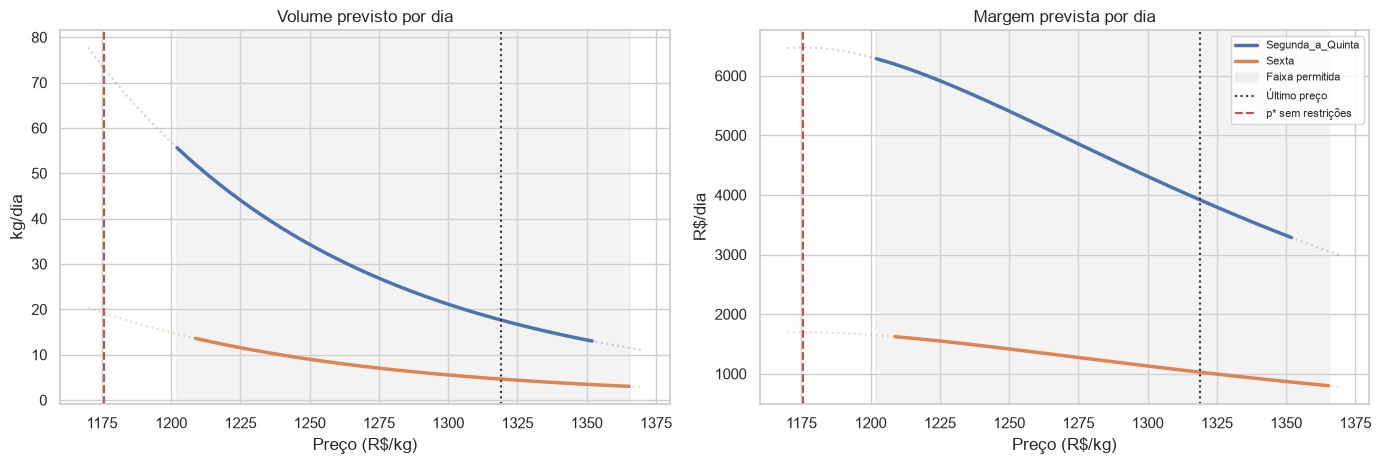

In [4]:
precos_grafico = np.linspace(1170, 1370, 300)
fig, eixos = plt.subplots(1, 2, figsize=(14, 4.8))
for contexto, cor in CORES.items():
    dentro = (precos_grafico >= suporte[contexto]['min']) & (precos_grafico <= suporte[contexto]['max'])
    for eixo, funcao in zip(eixos, [volume_previsto, margem_prevista]):
        valores = funcao(precos_grafico, contexto)
        eixo.plot(precos_grafico, valores, color=cor, alpha=0.3, linestyle=':')
        eixo.plot(precos_grafico[dentro], valores[dentro], color=cor, linewidth=2.5, label=contexto)
for eixo in eixos:
    eixo.axvspan(horizonte['preco_min'].min(), horizonte['preco_max'].max(),
                 color='#dddddd', alpha=0.35, label='Faixa permitida')
    eixo.axvline(PRECO_ANTERIOR, color='#333333', linestyle=':', label='Último preço')
    eixo.axvline(PRECO_OTIMO_LIVRE, color='#c44e52', linestyle='--', label='p* sem restrições')
    eixo.set_xlabel('Preço (R$/kg)')
eixos[0].set(title='Volume previsto por dia', ylabel='kg/dia')
eixos[1].set(title='Margem prevista por dia', ylabel='R$/dia')
eixos[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES_DIR / '031_curva_horizonte.png', dpi=160, bbox_inches='tight')
plt.show()

**Resultado da curva.** No último preço praticado, a curva prevê `17,67 kg` por dia de segunda a quinta e `4,63 kg` na sexta, com margens diárias de `R$ 3.917` e `R$ 1.026`. O preço ótimo sem restrições é `R$ 1.175,70/kg`, abaixo do menor preço permitido (`R$ 1.201,63` de segunda a quinta e `R$ 1.208,37` na sexta).

O gráfico da direita mostra a consequência: em toda a faixa permitida, **a margem diária cresce quando o preço cai**. Isso acontece porque a elasticidade é alta (`-12,36`): uma redução de 1% no preço aumenta o volume em cerca de 12%, o que mais do que compensa a margem menor por kg. Assim, dentro da faixa, baixar o preço aumenta ao mesmo tempo o volume e a margem. Essa conclusão vale para esta curva e este custo; com uma elasticidade menor, o preço ótimo poderia ficar dentro da faixa.

## 4. Grade de preços

O modelo escolhe, para cada dia, um preço de uma grade. Isso transforma o problema em uma escolha
entre opções cujo volume e cuja margem podem ser calculados antes, o que torna todas as restrições
lineares e permite encontrar o melhor plano da grade com garantia.

A grade tem passo de R$ 0,50 e é alinhada ao último preço praticado: todos os preços da forma
$p^{ant} + 0{,}50\,j$. Assim, uma redução de exatamente R$ 2 por dia cai sempre sobre a grade.
Para cada dia e cada preço são calculados o volume, a margem e se o preço está dentro da faixa
permitida para aquele dia.

In [5]:
def montar_grade(horizonte, passo=PASSO_GRADE):
    inicio = int(np.ceil((horizonte['preco_min'].min() - PRECO_ANTERIOR) / passo))
    fim = int(np.floor((horizonte['preco_max'].max() - PRECO_ANTERIOR) / passo))
    precos = PRECO_ANTERIOR + passo * np.arange(inicio, fim + 1)
    volume = np.array([volume_previsto(precos, ctx) for ctx in horizonte['contexto']])
    margem = ((1 - IMPOSTO) * precos[None, :] - CUSTO_KG) * volume
    permitido = (
        (precos[None, :] >= horizonte['preco_min'].to_numpy()[:, None] - 1e-9)
        & (precos[None, :] <= horizonte['preco_max'].to_numpy()[:, None] + 1e-9)
    )
    return precos, volume, margem, permitido


PRECOS_GRADE, VOLUME_GRADE, MARGEM_GRADE, PERMITIDO = montar_grade(horizonte)
DIAS, PONTOS = VOLUME_GRADE.shape
print(f'Preços na grade: {PONTOS} (de R$ {PRECOS_GRADE.min():.2f} a R$ {PRECOS_GRADE.max():.2f})')
print(f'Variáveis de decisão: {DIAS} dias × {PONTOS} preços = {DIAS * PONTOS}')
display(pd.DataFrame({
    'Dia': horizonte['data'].dt.strftime('%d/%m') + ' ' + horizonte['dia_semana'],
    'Preços permitidos': PERMITIDO.sum(axis=1),
    'Menor preço permitido': [PRECOS_GRADE[linha].min() for linha in PERMITIDO],
    'Maior preço permitido': [PRECOS_GRADE[linha].max() for linha in PERMITIDO],
}).set_index('Dia').round(2))

Preços na grade: 328 (de R$ 1201.92 a R$ 1365.42)
Variáveis de decisão: 10 dias × 328 preços = 3280


,Preços permitidos,Menor preço permitido,Maior preço permitido
Dia,,,
03/11 Segunda,302,1201.92,1352.42
04/11 Terça,302,1201.92,1352.42
05/11 Quarta,302,1201.92,1352.42
06/11 Quinta,302,1201.92,1352.42
07/11 Sexta,315,1208.42,1365.42
10/11 Segunda,302,1201.92,1352.42
11/11 Terça,302,1201.92,1352.42
12/11 Quarta,302,1201.92,1352.42
13/11 Quinta,302,1201.92,1352.42


O mapa de calor mostra a tabela que o otimizador recebe: a margem prevista de cada dia em cada
preço permitido. As sextas-feiras aparecem mais claras porque vendem cerca de um quarto do volume
dos outros dias úteis.

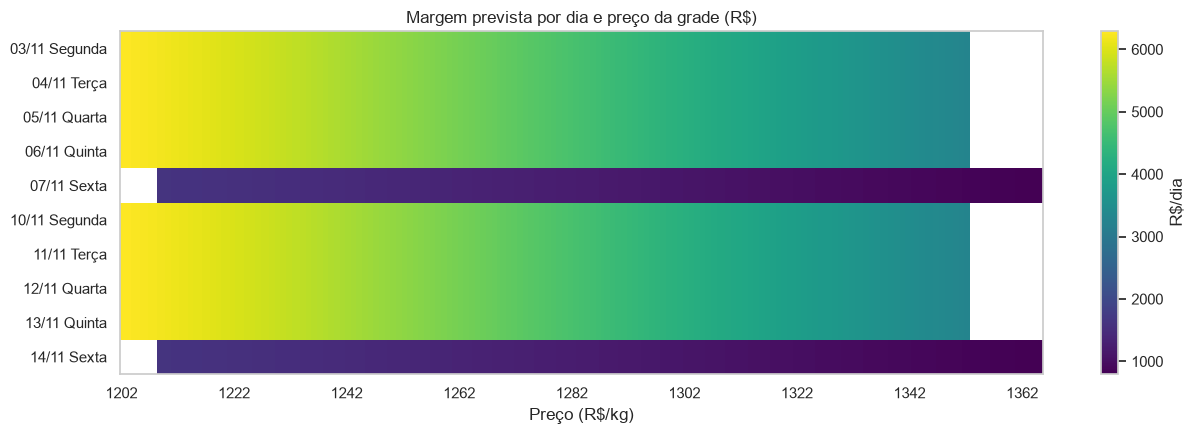

In [6]:
mapa = np.where(PERMITIDO, MARGEM_GRADE, np.nan)
fig, ax = plt.subplots(figsize=(13, 4.5))
imagem = ax.imshow(mapa, aspect='auto', cmap='viridis', interpolation='nearest')
marcas = np.arange(0, PONTOS, 40)
ax.set_xticks(marcas, [f'{PRECOS_GRADE[i]:.0f}' for i in marcas])
ax.set_yticks(range(DIAS), horizonte['data'].dt.strftime('%d/%m') + ' ' + horizonte['dia_semana'])
ax.set(title='Margem prevista por dia e preço da grade (R$)', xlabel='Preço (R$/kg)')
ax.grid(False)
fig.colorbar(imagem, ax=ax, label='R$/dia')
fig.tight_layout()
fig.savefig(FIGURES_DIR / '031_grade_margem.png', dpi=160, bbox_inches='tight')
plt.show()

**Resultado da grade.** A grade tem `328` preços, de `R$ 1.201,92` a `R$ 1.365,42`, o que dá `3.280` variáveis de decisão. De segunda a quinta são permitidos `302` preços e na sexta, `315`, porque a faixa da sexta é deslocada para cima. No mapa de calor, a margem diminui da esquerda para a direita em todos os dias, confirmando que preços menores dão mais margem. As sextas valem cerca de um quarto dos demais dias, porque vendem menos.

## 5. Planos de referência

Antes do otimizador, dois planos simples servem de comparação:

- **manter o preço:** repetir R$ 1.318,92 em todos os dias;
- **rampa de R$ 2:** reduzir o preço em R$ 2 por dia, o máximo permitido pela regra.

As funções abaixo avaliam qualquer plano de preços: volume e margem por dia, volume semanal e se o
plano cumpre as regras. Elas também serão usadas para conferir os planos do otimizador.

In [7]:
def criar_regras(delta=DELTA_REGRA, tol_inf=TOLERANCIA, tol_sup=TOLERANCIA,
                 delta_transicao=None, dias_transicao=0, ancora=True):
    limites = np.full(DIAS, float(delta))
    if dias_transicao:
        limites[:dias_transicao] = float(delta_transicao)
    if not ancora:
        limites[0] = np.inf
    return {
        'delta': limites,
        'q_min': META_KG * (1 - tol_inf),
        'q_max': META_KG * (1 + tol_sup),
    }


def avaliar_plano(precos_plano, nome):
    plano = horizonte[['data', 'dia_semana', 'semana', 'contexto']].copy()
    plano['plano'] = nome
    plano['preco_kg'] = np.asarray(precos_plano, dtype=float)
    plano['volume_kg'] = [
        volume_previsto(preco, ctx) for preco, ctx in zip(plano['preco_kg'], plano['contexto'])
    ]
    plano['margem_rs'] = ((1 - IMPOSTO) * plano['preco_kg'] - CUSTO_KG) * plano['volume_kg']
    plano['variacao_rs'] = plano['preco_kg'].diff()
    plano.loc[plano.index[0], 'variacao_rs'] = plano['preco_kg'].iloc[0] - PRECO_ANTERIOR
    return plano


def resumir_plano(plano, regras):
    semanal = plano.groupby('semana')['volume_kg'].sum()
    variacao_ok = (plano['variacao_rs'].abs().to_numpy() <= regras['delta'] + 1e-6).all()
    meta_ok = ((semanal >= regras['q_min'] - 1e-6) & (semanal <= regras['q_max'] + 1e-6)).all()
    faixa_ok = (
        (plano['preco_kg'] >= horizonte['preco_min'] - 1e-6)
        & (plano['preco_kg'] <= horizonte['preco_max'] + 1e-6)
    ).all()
    return {
        'Plano': plano['plano'].iloc[0],
        'Volume semana 1 (kg)': semanal.loc[1],
        'Volume semana 2 (kg)': semanal.loc[2],
        'Margem (R$)': plano['margem_rs'].sum(),
        'Preço médio (R$/kg)': plano['preco_kg'].mean(),
        'Maior variação diária (R$)': plano['variacao_rs'].abs().max(),
        'Respeita variação e faixa': bool(variacao_ok and faixa_ok),
        'Cumpre a meta': bool(meta_ok),
    }


REGRAS_ATUAIS = criar_regras()
plano_constante = avaliar_plano(np.full(DIAS, PRECO_ANTERIOR), 'Manter o preço')
plano_rampa = avaliar_plano(PRECO_ANTERIOR - DELTA_REGRA * np.arange(1, DIAS + 1), 'Rampa de R$ 2')
referencias = pd.DataFrame([
    resumir_plano(plano, REGRAS_ATUAIS) for plano in [plano_constante, plano_rampa]
]).set_index('Plano')
display(referencias.round(2))

,Volume semana 1 (kg),Volume semana 2 (kg),Margem (R$),Preço médio (R$/kg),Maior variação diária (R$),Respeita variação e faixa,Cumpre a meta
Plano,,,,,,,
Manter o preço,75.33,75.33,33388.87,1318.92,0.0,True,False
Rampa de R$ 2,79.20,87.05,35206.40,1307.92,2.0,True,False


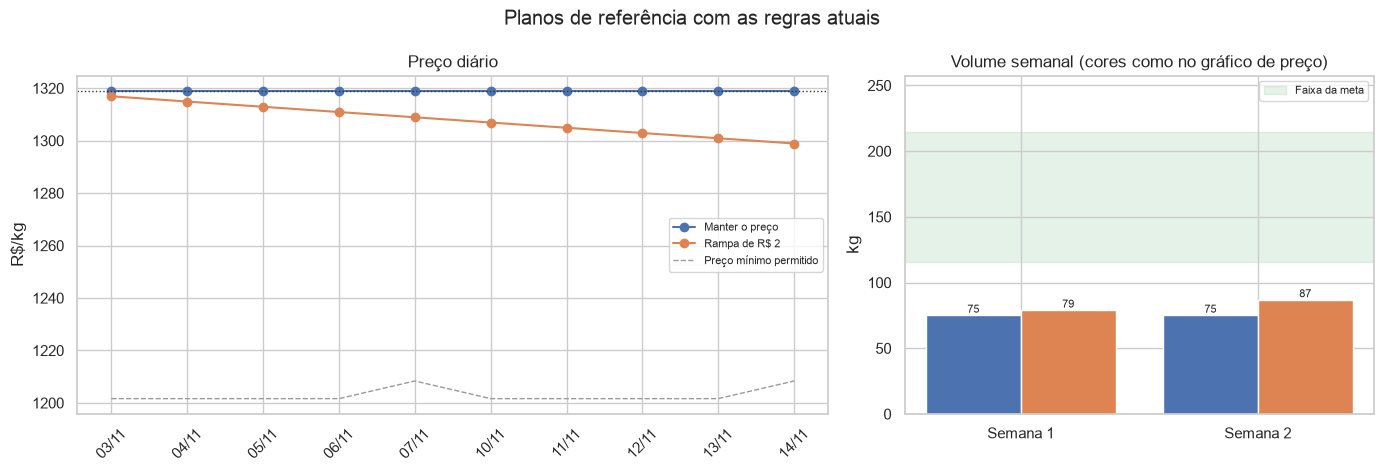

In [8]:
def grafico_planos(planos, regras, titulo, arquivo):
    fig, eixos = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [1.6, 1]})
    rotulos = horizonte['data'].dt.strftime('%d/%m')
    for plano in planos:
        eixos[0].plot(rotulos, plano['preco_kg'], marker='o', label=plano['plano'].iloc[0])
    eixos[0].axhline(PRECO_ANTERIOR, color='#333333', linestyle=':', linewidth=1)
    eixos[0].plot(rotulos, horizonte['preco_min'], color='#999999', linestyle='--',
                  linewidth=1, label='Preço mínimo permitido')
    eixos[0].set(title='Preço diário', ylabel='R$/kg')
    eixos[0].tick_params(axis='x', rotation=45)
    eixos[0].legend(fontsize=8)

    largura = 0.8 / len(planos)
    for posicao, plano in enumerate(planos):
        semanal = plano.groupby('semana')['volume_kg'].sum()
        barras = eixos[1].bar(
            np.array([1, 2]) + (posicao - (len(planos) - 1) / 2) * largura, semanal,
            width=largura, zorder=2,
        )
        eixos[1].bar_label(barras, fmt='%.0f', fontsize=8)
    eixos[1].axhspan(regras['q_min'], regras['q_max'], color='#55a868', alpha=0.15,
                     zorder=0, label='Faixa da meta')
    eixos[1].set(title='Volume semanal (cores como no gráfico de preço)', ylabel='kg',
                 xticks=[1, 2], xticklabels=['Semana 1', 'Semana 2'],
                 ylim=(0, regras['q_max'] * 1.2))
    eixos[1].legend(fontsize=8)
    fig.suptitle(titulo)
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / arquivo, dpi=160, bbox_inches='tight')
    plt.show()


grafico_planos(
    [plano_constante, plano_rampa], REGRAS_ATUAIS,
    'Planos de referência com as regras atuais', '031_referencias.png',
)

**Resultado das referências.** Manter o preço de 31/10 gera `75,3 kg` por semana e margem de `R$ 33.389`. A rampa de R$ 2 por dia gera `79,2 kg` na primeira semana, `87,1 kg` na segunda e margem de `R$ 35.206`. Os dois planos respeitam a variação e a faixa de preço, mas **nenhum cumpre a meta**: ambos ficam abaixo do mínimo de `115,5 kg` nas duas semanas. A rampa já indica que nem a maior redução permitida chega perto do mínimo.

## 6. Montagem do modelo

O modelo é montado por partes. A decisão é uma variável binária $x_{tk}$, que vale 1 quando o dia
$t$ usa o preço $k$ da grade. Cada parte abaixo cria um bloco de restrições, e a resolução apenas os
reúne.

### 6.1 Preços permitidos e âncora

Preços fora da faixa do dia não podem ser escolhidos. No primeiro dia, também ficam bloqueados os
preços que se afastam do último preço praticado mais que o limite permitido: essa é a âncora.

In [9]:
def precos_permitidos(regras):
    permitido = PERMITIDO.copy()
    permitido[0] &= np.abs(PRECOS_GRADE - PRECO_ANTERIOR) <= regras['delta'][0] + 1e-9
    return permitido


exemplo = precos_permitidos(REGRAS_ATUAIS)
print(
    'Preços permitidos no primeiro dia com a âncora atual: '
    f'{PRECOS_GRADE[exemplo[0]].min():.2f} a {PRECOS_GRADE[exemplo[0]].max():.2f}'
)

Preços permitidos no primeiro dia com a âncora atual: 1316.92 a 1320.92


### 6.2 Um preço por dia

Cada dia escolhe exatamente um preço: $\sum_k x_{tk} = 1$.

In [10]:
def restricao_um_preco():
    matriz = lil_matrix((DIAS, DIAS * PONTOS))
    for dia in range(DIAS):
        matriz[dia, dia * PONTOS:(dia + 1) * PONTOS] = 1
    return matriz.tocsr(), np.ones(DIAS), np.ones(DIAS)


print(f'Restrições de um preço por dia: {restricao_um_preco()[0].shape[0]}')

Restrições de um preço por dia: 10


### 6.3 Variação entre dias consecutivos

O preço do dia é $p_t = \sum_k P_k x_{tk}$. A diferença entre dois dias consecutivos fica entre
$-\Delta_t$ e $+\Delta_t$. A relação com o preço anterior ao horizonte já foi tratada na seção 6.1.
Sexta-feira e a segunda-feira seguinte são consideradas dias consecutivos.

In [11]:
def restricao_variacao(regras):
    dias = [dia for dia in range(1, DIAS) if np.isfinite(regras['delta'][dia])]
    matriz = lil_matrix((len(dias), DIAS * PONTOS))
    for linha, dia in enumerate(dias):
        matriz[linha, dia * PONTOS:(dia + 1) * PONTOS] = PRECOS_GRADE
        matriz[linha, (dia - 1) * PONTOS:dia * PONTOS] = -PRECOS_GRADE
    limite = regras['delta'][dias]
    return matriz.tocsr(), -limite, limite


print(f'Restrições de variação: {restricao_variacao(REGRAS_ATUAIS)[0].shape[0]}')

Restrições de variação: 9


### 6.4 Meta semanal

O volume de cada semana é a soma dos volumes da grade escolhidos nos seus dias e deve ficar entre o
mínimo e o máximo da meta.

In [12]:
def restricao_meta(regras):
    matriz = lil_matrix((2, DIAS * PONTOS))
    for linha, semana in enumerate([1, 2]):
        for dia in np.flatnonzero(horizonte['semana'].to_numpy() == semana):
            matriz[linha, dia * PONTOS:(dia + 1) * PONTOS] = VOLUME_GRADE[dia]
    return matriz.tocsr(), np.full(2, regras['q_min']), np.full(2, regras['q_max'])


print(
    f"Faixa semanal com as regras atuais: {REGRAS_ATUAIS['q_min']:.1f} "
    f"a {REGRAS_ATUAIS['q_max']:.1f} kg"
)

Faixa semanal com as regras atuais: 115.5 a 214.5 kg


### 6.5 Objetivo e resolução

O objetivo soma as margens da grade escolhidas, $\sum_{t,k} G_{tk}x_{tk}$. O solver HiGHS, chamado
por `scipy.optimize.milp`, encontra o melhor plano da grade dentro das tolerâncias de otimalidade.
Cada resolução reporta o status, o gap de otimalidade e o tempo.

A mesma função permite trocar o objetivo por volume total e retirar a meta. Essa variação é usada no
diagnóstico da seção 8.

In [13]:
STATUS_MILP = {
    0: 'ótimo encontrado', 1: 'limite de tempo ou iterações', 2: 'inviável',
    3: 'ilimitado', 4: 'outro',
}


def resolver_estrito(regras, objetivo='margem', com_meta=True):
    blocos = [restricao_um_preco(), restricao_variacao(regras)]
    if com_meta:
        blocos.append(restricao_meta(regras))
    matriz = vstack([bloco[0] for bloco in blocos]).tocsr()
    inferior = np.concatenate([bloco[1] for bloco in blocos])
    superior = np.concatenate([bloco[2] for bloco in blocos])
    ganho = MARGEM_GRADE if objetivo == 'margem' else VOLUME_GRADE

    inicio = time.perf_counter()
    resposta = milp(
        -ganho.ravel(),
        constraints=LinearConstraint(matriz, inferior, superior),
        integrality=np.ones(DIAS * PONTOS),
        bounds=Bounds(0, precos_permitidos(regras).ravel().astype(float)),
        options={'time_limit': LIMITE_TEMPO_S},
    )
    saida = {
        'status': STATUS_MILP.get(resposta.status, str(resposta.status)),
        'viavel': resposta.x is not None,
        'mip_gap': getattr(resposta, 'mip_gap', np.nan),
        'tempo_s': time.perf_counter() - inicio,
    }
    if resposta.x is not None:
        escolha = resposta.x.reshape(DIAS, PONTOS).argmax(axis=1)
        saida['precos'] = PRECOS_GRADE[escolha]
    return saida

## 7. Resolução com as regras atuais

O modelo é resolvido com meta de 165 kg ± 30%, variação máxima de R$ 2 e âncora no último preço.

In [14]:
solucao_atual = resolver_estrito(REGRAS_ATUAIS)
print(f"Status: {solucao_atual['status']}")
print(f"Tempo: {solucao_atual['tempo_s']:.2f} s")

Status: inviável
Tempo: 1.27 s


**Resultado da resolução.** O solver concluiu em pouco mais de 1 segundo que **o problema é inviável**: não existe nenhuma sequência de preços que cumpra a meta semanal, a variação de R$ 2, a âncora e a faixa de preço ao mesmo tempo. Inviável não é um erro do modelo; é uma resposta: com as regras atuais, a meta não pode ser atingida segundo a curva de demanda.

## 8. Diagnóstico da inviabilidade

Se não existe plano que cumpra todas as regras, a pergunta seguinte é qual regra impede. O
diagnóstico retira a meta e pede ao modelo o **maior volume possível** respeitando apenas a variação,
a âncora e a faixa de preço. Se nem esse volume alcança o mínimo semanal, nenhum plano alcançará.

Como o volume cai quando o preço sobe, o maior volume é obtido baixando o preço o máximo permitido
todos os dias. O modelo deve, portanto, reproduzir a rampa de R$ 2 da seção 5.

In [15]:
diagnostico = resolver_estrito(REGRAS_ATUAIS, objetivo='volume', com_meta=False)
plano_volume_maximo = avaliar_plano(diagnostico['precos'], 'Maior volume possível')
semanal_maximo = plano_volume_maximo.groupby('semana')['volume_kg'].sum()
tabela_diagnostico = pd.DataFrame({
    'Volume máximo possível (kg)': semanal_maximo,
    'Mínimo exigido (kg)': REGRAS_ATUAIS['q_min'],
    'Falta (kg)': (REGRAS_ATUAIS['q_min'] - semanal_maximo).clip(lower=0),
})
tabela_diagnostico.index = ['Semana 1', 'Semana 2']
display(tabela_diagnostico.round(2))
print(f"Status do diagnóstico: {diagnostico['status']}")
print(
    'O plano de maior volume coincide com a rampa de R$ 2: '
    f"{np.allclose(diagnostico['precos'], plano_rampa['preco_kg'])}"
)
tolerancia_necessaria = 1 - semanal_maximo.min() / META_KG
print(f'Tolerância necessária para viabilizar com as demais regras fixas: {tolerancia_necessaria:.1%}')

,Volume máximo possível (kg),Mínimo exigido (kg),Falta (kg)
Semana 1,79.20,115.5,36.30
Semana 2,87.05,115.5,28.45


Status do diagnóstico: ótimo encontrado
O plano de maior volume coincide com a rampa de R$ 2: True
Tolerância necessária para viabilizar com as demais regras fixas: 52.0%


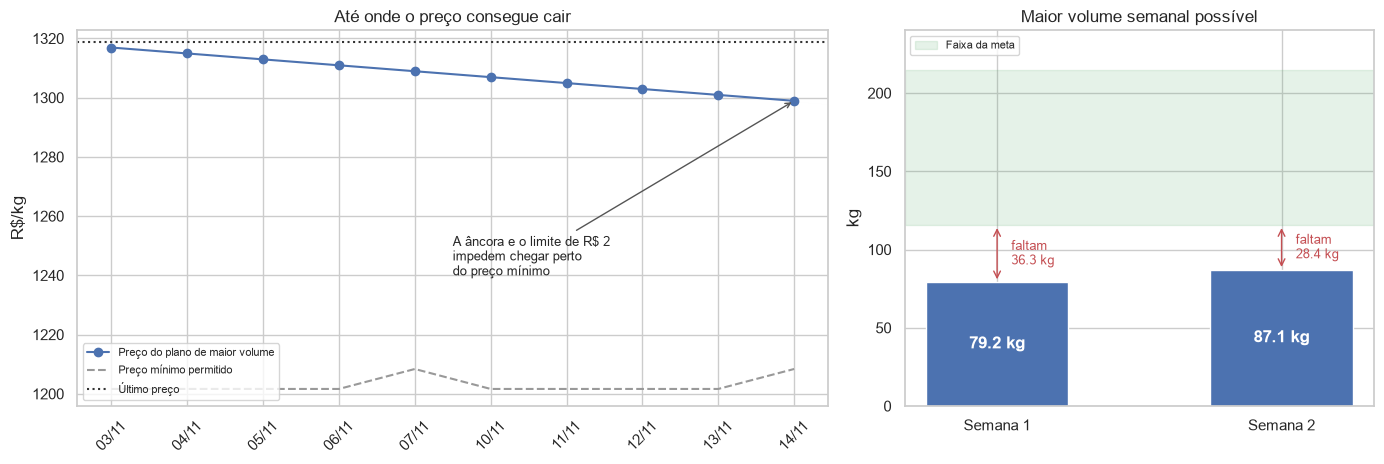

In [16]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [1.6, 1]})
rotulos = horizonte['data'].dt.strftime('%d/%m')
eixos[0].plot(rotulos, plano_volume_maximo['preco_kg'], marker='o', color='#4c72b0',
              label='Preço do plano de maior volume')
eixos[0].plot(rotulos, horizonte['preco_min'], color='#999999', linestyle='--',
              label='Preço mínimo permitido')
eixos[0].axhline(PRECO_ANTERIOR, color='#333333', linestyle=':', label='Último preço')
eixos[0].annotate(
    'A âncora e o limite de R$ 2\nimpedem chegar perto\ndo preço mínimo',
    xy=(9, plano_volume_maximo['preco_kg'].iloc[-1]), xytext=(4.5, 1240),
    arrowprops={'arrowstyle': '->', 'color': '#555555'}, fontsize=9,
)
eixos[0].set(title='Até onde o preço consegue cair', ylabel='R$/kg')
eixos[0].tick_params(axis='x', rotation=45)
eixos[0].legend(fontsize=8, loc='lower left')

barras = eixos[1].bar(['Semana 1', 'Semana 2'], semanal_maximo, color='#4c72b0', width=0.5)
eixos[1].bar_label(barras, fmt='%.1f kg', label_type='center', color='white', fontweight='bold')
eixos[1].axhspan(REGRAS_ATUAIS['q_min'], REGRAS_ATUAIS['q_max'], color='#55a868', alpha=0.15,
                 label='Faixa da meta')
for posicao, falta in enumerate(tabela_diagnostico['Falta (kg)']):
    eixos[1].annotate('', xy=(posicao, REGRAS_ATUAIS['q_min']), xytext=(posicao, semanal_maximo.iloc[posicao]),
                      arrowprops={'arrowstyle': '<->', 'color': '#c44e52'})
    eixos[1].text(posicao + 0.05, (REGRAS_ATUAIS['q_min'] + semanal_maximo.iloc[posicao]) / 2,
                  f'faltam\n{falta:.1f} kg', color='#c44e52', fontsize=9, va='center')
eixos[1].set(title='Maior volume semanal possível', ylabel='kg', ylim=(0, 240))
eixos[1].legend(fontsize=8, loc='upper left')
fig.tight_layout()
fig.savefig(FIGURES_DIR / '031_diagnostico_inviabilidade.png', dpi=160, bbox_inches='tight')
plt.show()

**Resultado do diagnóstico.** Sem a meta, o maior volume possível é `79,20 kg` na primeira semana e `87,05 kg` na segunda, e o modelo reproduziu exatamente a rampa de R$ 2. Faltam `36,3 kg` na primeira semana e `28,5 kg` na segunda para chegar ao mínimo de `115,5 kg`.

O gráfico mostra a causa. Partindo de `R$ 1.318,92` e descendo `R$ 2` por dia, o preço chega a `R$ 1.298,92` no último dia, ainda perto de R$ 100 acima do preço mínimo permitido. **A inviabilidade vem da combinação de três fatores:** o preço de partida alto, o limite de redução diária pequeno e o mínimo semanal exigido. Mudar qualquer um deles pode tornar a meta viável. Mantidos os outros dois, o mínimo semanal só seria atingível com tolerância de `52%`, ou seja, aceitando vender cerca de `79 kg` por semana.

## 9. Verificação com regras liberadas

Para confirmar que o modelo encontra soluções quando elas existem, ele é resolvido com quatro
alterações isoladas das regras, cada uma suficiente para viabilizar a meta:

1. variação máxima de R$ 20 em todos os dias;
2. variação de R$ 16,50 apenas nos cinco dias da primeira semana (janela de transição), voltando a
   R$ 2 na segunda;
3. mínimo semanal com tolerância de 53%, mantendo o máximo em 214,5 kg;
4. âncora removida: o primeiro dia pode começar em qualquer preço da faixa, e depois vale R$ 2.

Os valores foram escolhidos ligeiramente acima dos mínimos calculados no planejamento, para que os
casos sejam viáveis na grade. Esta seção não compara as alterações como propostas de negociação;
essa análise, com curvas completas, é o objetivo do notebook 3.2.

In [17]:
casos = {
    'Variação de R$ 20': criar_regras(delta=20),
    'Transição de R$ 16,50 na semana 1': criar_regras(delta_transicao=16.5, dias_transicao=5),
    'Tolerância de 53% no mínimo': criar_regras(tol_inf=0.53),
    'Sem âncora': criar_regras(ancora=False),
}
planos_liberados = {}
linhas_casos = []
for nome, regras in casos.items():
    solucao = resolver_estrito(regras)
    linha = {
        'Caso': nome, 'Status': solucao['status'], 'Gap MIP': solucao['mip_gap'],
        'Tempo (s)': solucao['tempo_s'],
    }
    if solucao['viavel']:
        plano = avaliar_plano(solucao['precos'], nome)
        planos_liberados[nome] = plano
        linha.update(resumir_plano(plano, regras))
        linha.pop('Plano')
    linhas_casos.append(linha)
resultado_casos = pd.DataFrame(linhas_casos).set_index('Caso')
resultado_casos.to_csv(TABLES_DIR / '031_regras_liberadas.csv')
display(resultado_casos.round(3))

,Status,Gap MIP,Tempo (s),Volume semana 1 (kg),Volume semana 2 (kg),Margem (R$),Preço médio (R$/kg),Maior variação diária (R$),Respeita variação e faixa,Cumpre a meta
Caso,,,,,,,,,,
Variação de R$ 20,ótimo encontrado,0.0,0.954,129.235,214.431,47721.677,1235.42,20.0,True,True
"Transição de R$ 16,50 na semana 1",ótimo encontrado,0.0,1.737,116.827,176.628,45402.292,1249.92,16.5,True,True
Tolerância de 53% no mínimo,ótimo encontrado,0.0,1.498,79.202,87.050,35206.402,1307.92,2.0,True,True
Sem âncora,ótimo encontrado,0.0,0.267,214.431,214.431,52370.446,1211.92,107.0,True,True


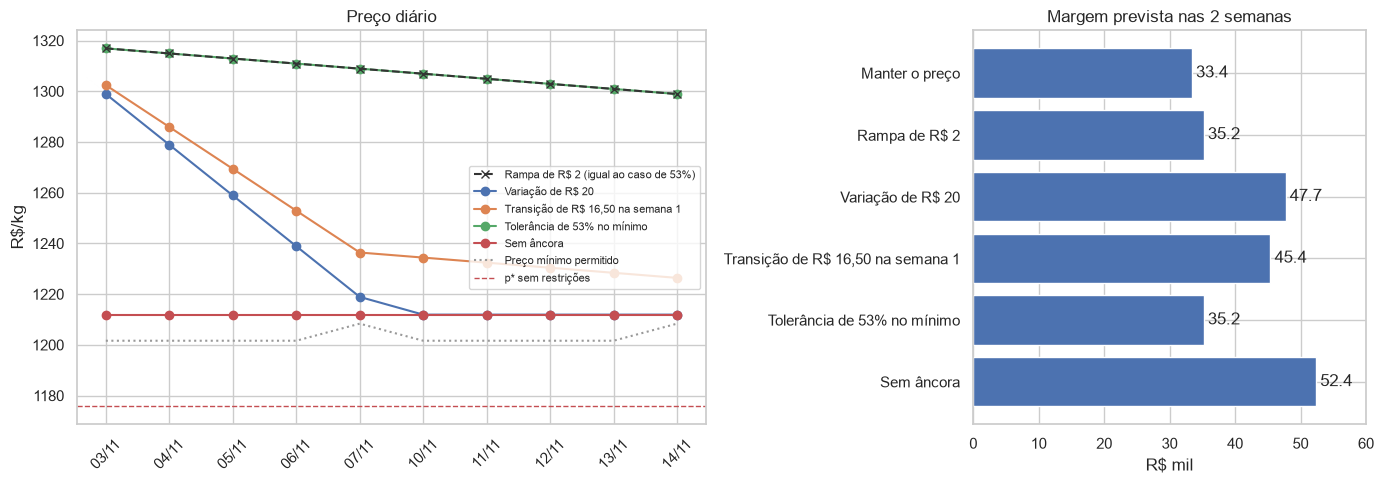

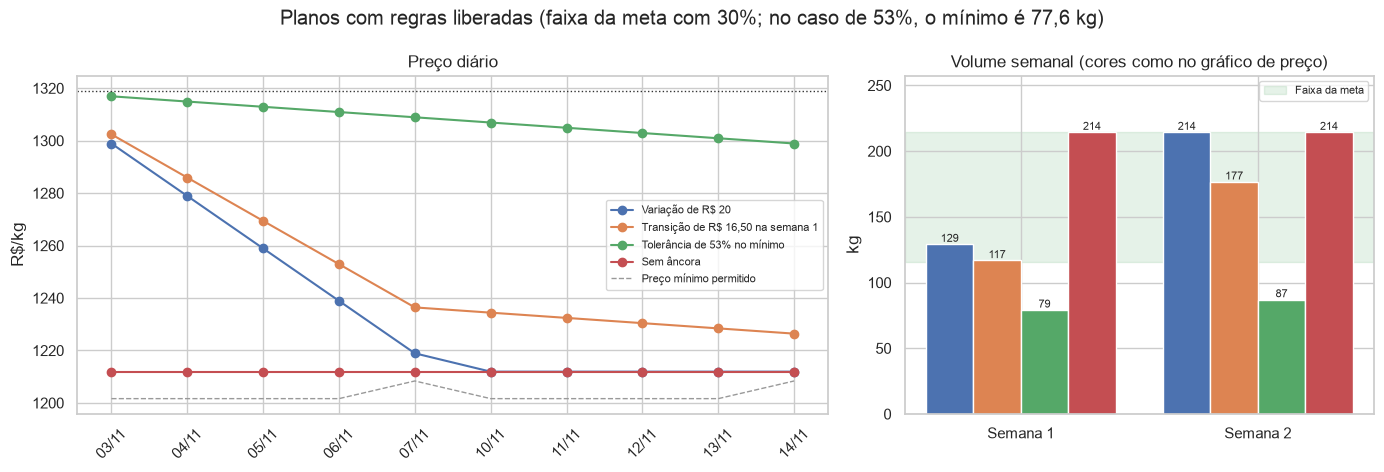

In [18]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [1.6, 1]})
rotulos = horizonte['data'].dt.strftime('%d/%m')
planos_grafico = [plano_rampa, *planos_liberados.values()]
for plano in planos_grafico:
    if plano['plano'].iloc[0] == 'Rampa de R$ 2':
        eixos[0].plot(rotulos, plano['preco_kg'], color='#333333', linestyle='--', marker='x',
                      zorder=5, label='Rampa de R$ 2 (igual ao caso de 53%)')
    else:
        eixos[0].plot(rotulos, plano['preco_kg'], marker='o', label=plano['plano'].iloc[0])
eixos[0].plot(rotulos, horizonte['preco_min'], color='#999999', linestyle=':', label='Preço mínimo permitido')
eixos[0].axhline(PRECO_OTIMO_LIVRE, color='#c44e52', linestyle='--', linewidth=1, label='p* sem restrições')
eixos[0].set(title='Preço diário', ylabel='R$/kg')
eixos[0].tick_params(axis='x', rotation=45)
eixos[0].legend(fontsize=8)

resumo_margem = pd.DataFrame([
    {'Plano': plano['plano'].iloc[0], 'Margem (R$ mil)': plano['margem_rs'].sum() / 1000}
    for plano in [plano_constante, *planos_grafico]
])
barras = eixos[1].barh(resumo_margem['Plano'], resumo_margem['Margem (R$ mil)'], color='#4c72b0')
eixos[1].bar_label(barras, fmt='%.1f', padding=3)
eixos[1].invert_yaxis()
eixos[1].set(title='Margem prevista nas 2 semanas', xlabel='R$ mil', xlim=(0, 60))
fig.tight_layout()
fig.savefig(FIGURES_DIR / '031_regras_liberadas.png', dpi=160, bbox_inches='tight')
plt.show()

grafico_planos(
    list(planos_liberados.values()), REGRAS_ATUAIS,
    'Planos com regras liberadas (faixa da meta com 30%; no caso de 53%, o mínimo é 77,6 kg)',
    '031_regras_liberadas_volume.png',
)

**Resultado das regras liberadas.** O modelo encontrou o plano ótimo nos quatro casos, com gap de otimalidade zero e menos de 2 segundos por resolução, o que confirma que ele funciona quando existem soluções.

| Caso | Semana 1 | Semana 2 | Margem | O que limita o plano |
|---|---:|---:|---:|---|
| Variação de R$ 20 | 129,2 kg | 214,4 kg | R$ 47.722 | O teto da meta na semana 2 |
| Transição de R$ 16,50 na semana 1 | 116,8 kg | 176,6 kg | R$ 45.402 | A volta para R$ 2 por dia na semana 2 |
| Tolerância de 53% no mínimo | 79,2 kg | 87,1 kg | R$ 35.206 | A rampa de R$ 2; o plano é igual à rampa |
| Sem âncora | 214,4 kg | 214,4 kg | R$ 52.370 | O teto da meta nas duas semanas |

Três leituras se destacam:

- **Flexibilizar apenas o mínimo semanal torna o plano viável, mas não muda a margem.** O plano ótimo continua sendo a rampa de R$ 2.
- **Liberar a variação, nas duas semanas ou só na primeira, é o que gera margem.** O preço cai rapidamente na primeira semana e o volume sobe até a faixa da meta.
- **Quando o preço pode cair livremente, o teto de `214,5 kg` passa a limitar.** Por isso, os planos sem âncora e com R$ 20 param em `R$ 1.211,92`, acima do preço mínimo permitido: baixar mais ultrapassaria o volume máximo da semana.

O caso sem âncora começa com uma redução de `R$ 107` no primeiro dia. Sua margem compara uma configuração que cumpre a meta com a regra atual, que não a cumpre; deve ser lida como diferença simulada entre configurações, não como ganho. A comparação completa das alavancas é feita no notebook 3.2.

## 10. Conclusões

1. **Com as regras atuais, o problema é inviável.** Nenhuma sequência de preços cumpre a meta de 165 kg ± 30% com variação de R$ 2 por dia a partir de R$ 1.318,92.
2. **A causa é a combinação entre preço de partida, limite de redução diária e mínimo semanal.** Mesmo descendo R$ 2 todos os dias, o maior volume possível é 79,2 kg e 87,1 kg por semana, contra o mínimo de 115,5 kg.
3. **Com esta curva, baixar o preço aumenta volume e margem ao mesmo tempo.** O preço ótimo sem restrições (R$ 1.175,70) está abaixo da faixa permitida. Por isso, meta mínima e margem puxam na mesma direção, e o plano de maior volume é também o de maior margem com as regras atuais.
4. **O modelo encontra o ótimo quando ele existe.** Com regras liberadas, todas as resoluções terminaram com gap zero em menos de 2 segundos.
5. **Flexibilizar só o mínimo semanal não melhora a margem; liberar a variação de preço, sim.** Com variação maior, o teto semanal de 214,5 kg passa a ser a restrição que limita a margem.
6. **Próximo passo (notebook 3.2):** tratar a inviabilidade com o modelo flexível e medir, em curvas, quanto negociar de cada regra, incluindo a âncora, e quanto de margem cada negociação libera.